# Marine Carbonate System Calculations: Uncertainty in pCO$_2$ from Alkalinity and Dissolved Inorganic Carbon with PyCO2SYS

__Matthew P. Humphreys__, Department of Ocean Systems (OCS), NIOZ Royal Netherlands Institute for Sea Research, Texel, the Netherlands

__Ernie R. Lewis__, Environmental and Climate Sciences Department, Brookhaven National Laboratory, Upton, NY, USA

__Jonathan D. Sharp__, Cooperative Institute for Climate, Ocean, and Ecosystem Studies, University of Washington, Seattle, WA, USA; Pacific Marine Environmental Laboratory, National Oceanic and Atmospheric Administration, Seattle, WA, USA

__Denis Pierrot__, Atlantic Oceanographic and Meteorological Laboratory, National Oceanic and Atmospheric Administration, Miami, FL, USA

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

It runs in Python 3 with numpy, scipy and matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, and takes about a minute. It reads stored data written with PyCO2SYS v1.8.3 (GPLv3), which the notebook does not need; see `DATA.md`.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

SEED = 2022                       # the only seed in this notebook (the data have their own saved seeds)
t_start = time.perf_counter()

### Summary

PyCO2SYS [[1]][R1] solves the marine carbonate system: from two measured parameters, here total alkalinity $A_T$ and dissolved inorganic carbon $T_C$, with temperature, salinity, pressure and nutrients, it computes pH, the partial pressure of CO$_2$ (pCO$_2$), the carbonate-mineral saturation states and the rest of the system, and it propagates standard uncertainties linearly with finite-difference derivatives. We treat 14 inputs as independent Gaussians, the six measured inputs with measurement uncertainties we chose and seven equilibrium constants and total borate with the standard uncertainties of Orr et al. [[2]][R2] that PyCO2SYS ships, and compute the active subspace of pCO$_2$ (and of pH and the two saturation states) from 1000 samples with checked finite-difference gradients, in two studies: a measurement-uncertainty study at the paper's Table 4 test conditions (1234 dbar), and a clearly labelled "ocean-wide" surface-ocean study (0 dbar) with a wide spread of $A_T$, $T_C$, temperature and salinity. Over measurement uncertainty the model is nearly linear and the active subspace of pCO$_2$ is one-dimensional ($\lambda_1/\lambda_2 = 1.10\times10^4$), led by the second dissociation constant of carbonic acid; in the surface-ocean study pCO$_2$ is one-dimensional by the default gap rule ($\lambda_1/\lambda_2 = 176.4$, the $T_C - A_T$ contrast with temperature), but the larger relative gap is after $\lambda_2$ ($\lambda_2/\lambda_3 = 1398$, mostly temperature), so a two-dimensional subspace is the better-separated one.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ normalized inputs with density $\rho$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T \rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. If the first $n$ eigenvalues are much larger than the rest, $f$ varies mostly along the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ and is nearly constant along $\mathbf W_2^T\mathbf x$, so a plot of $f$ against $\mathbf y$ (a *sufficient summary plot*) shows the main trend, and a surrogate in $\mathbf y$ can replace $f$. For Gaussian inputs, $\mathrm{trace}(\mathbf C) = \sum_i \lambda_i$ is the sum of the squared sd-scaled derivatives, so for a linear $f$ it equals the variance of $f$ given by linear uncertainty propagation, and $\mathbf C$ has rank one. We estimate $\mathbf C$ by the sample average of gradient outer products and assess it with the bootstrap. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

### The model

**Equations.** PyCO2SYS [[1]][R1] (Sect. 2–3, Appendices B–D) solves for the hydrogen ion content $h = [\mathrm{H^+}]$ from the alkalinity equation
$$
A_T = [\mathrm{HCO_3^-}] + 2[\mathrm{CO_3^{2-}}] + [\mathrm{B(OH)_4^-}] + [\mathrm{OH^-}] - [\mathrm{H^+}]_\mathrm{free} + (\text{phosphate, silicate, ammonia, sulfide, sulfate and fluoride terms}),
$$
with the carbonate species fixed by $T_C$ and the stoichiometric constants,
$$
[\mathrm{HCO_3^-}] = \frac{T_C K_1^* h}{h^2 + K_1^* h + K_1^*K_2^*},\quad
[\mathrm{CO_3^{2-}}] = \frac{T_C K_1^*K_2^*}{h^2 + K_1^* h + K_1^*K_2^*},\quad
[\mathrm{CO_2(aq)}] = \frac{T_C h^2}{h^2 + K_1^* h + K_1^*K_2^*},\quad
[\mathrm{B(OH)_4^-}] = \frac{B_T K_B^*}{h + K_B^*},\quad [\mathrm{OH^-}] = \frac{K_w^*}{h},
$$
by an iterative (Newton) solver with a tolerance of $10^{-8}$ in pH (Sect. 3.1; Table 4 caption). Then $f\mathrm{CO_2} = [\mathrm{CO_2(aq)}]/K_0^*$, $p\mathrm{CO_2} = f\mathrm{CO_2}/G$ with the fugacity factor $G$, pH $= -\log_{10} h$ on the total scale, and $\Omega = [\mathrm{Ca^{2+}}][\mathrm{CO_3^{2-}}]/K_{sp}^*$ for aragonite and calcite. The constants $K^*$ are parameterisations in temperature $T$, salinity $S$ and pressure $P$ (Tables 1–3 of [[1]][R1]); the totals $B_T$, $[\mathrm{Ca^{2+}}]$, sulfate and fluoride follow from $S$.

**Conditions and options.** The centre of both studies is the paper's round-robin test point (Table 4, p. 25): $A_T = 2300$, $T_C = 2100$ µmol kg$^{-1}$, $S = 33$, $T = 22$ °C, total silicate 10 and total phosphate 1 µmol kg$^{-1}$, with total ammonia 2 and total sulfide 3 µmol kg$^{-1}$ held. The **measurement study** keeps the table's pressure, $P = 1234$ dbar. That is a synthetic test point (22 °C water does not occur at 1234 dbar in the ocean), which is harmless for an uncertainty study at one water sample. The **ocean-wide study** spreads temperature over 6–37 °C, which only the upper ocean reaches, so it is a **surface-ocean study at $P = 0$ dbar**. Pressure matters: at the nominal point, going from 1234 to 0 dbar raises $\Omega_\mathrm{ar}$ by 20.5 % (printed below). The options are those of PyCO2SYS v1.8.0, the version of the paper. Its defaults are the paper's "default parameterisation options": $K_1^*, K_2^*$ of Sulpis et al. [[3]][R3] (`opt_k_carbonic=16`), total borate of Uppström [[4]][R4] (`opt_total_borate=1`), $K_{HF}^*$ of Dickson and Riley [[5]][R5] (`opt_k_fluoride=1`), $K_{HSO_4}^*$ of Dickson [[6]][R6] (`opt_k_bisulfate=1`), the 2018 CODATA gas constant, and no pressure correction of $K_0^*$ (`opt_pressured_kCO2=0`), on the total pH scale. v1.8.3 changed some defaults, so we set these explicitly. The paper's round-robin script (`manuscript/round_robin.py` in the v1.8.0 release [[7]][R7]) also adds two hypothetical acid–base systems ("alpha", total 5 µmol kg$^{-1}$, $K = 10^{-4}$; "beta", total 6 µmol kg$^{-1}$, $K = 10^{-8}$) that the Table 4 caption does not list. They are not seawater constituents, so we leave them out of both studies. With them added, these options reproduce every printed Table 4 value (see the comparison below).

**Inputs** ($m = 14$, independent Gaussian). The six measured inputs, and seven constants and total borate. An uncertain constant enters as an offset of its parameterisation, $K^* = K^*_\mathrm{param}(T, S, P)\,10^{-\delta pK}$, so $\delta pK$ is the error of $pK^* = -\log_{10}K^*$ and has the standard uncertainty of Orr et al. [[2]][R2] (PyCO2SYS's `uncertainty_OEDG18`; also the defaults of seacarb's `errors()` [[9]][R9]); total borate is $B_T = f_B\,B_{T,\mathrm{param}}(S)$ with a fractional uncertainty of 2 %. All other constants follow their parameterisations. PyCO2SYS uses user-given constants "as-is" ([[1]][R1], p. 19), which is how the offsets are applied. Orr et al. (2018) predate Sulpis et al. (2020), so their uncertainties for $pK_1^*$ and $pK_2^*$ (0.0075 and 0.015) were not assessed for the Sulpis parameterisation; applying them to it is our assumption. The constants are naturally on a log scale, and every input, measured or not, is scaled by its own standard deviation (the library's Gaussian normalization, $x_i \mapsto (x_i - \mu_i)/\sigma_i$).

The paper gives no measurement uncertainties; they are our choice for high-quality ship-based data: 2 µmol kg$^{-1}$ for $A_T$ and $T_C$, 0.05 °C for temperature (the value in PyCO2SYS's documentation example; 5 times seacarb's `errors()` default of 0.01 °C [[9]][R9]), 0.01 for salinity (seacarb's `errors()` default, `eS = 0.01`), and 4 % for silicate and phosphate. The **ocean-wide study** keeps the constants' uncertainties and spreads the measured inputs widely and independently around the same centre ($A_T$, $T_C$ sd 50 µmol kg$^{-1}$, $T$ sd 5 °C, $S$ sd 1, silicate sd 2, phosphate sd 0.2 µmol kg$^{-1}$), at the sea surface ($P = 0$ dbar). It is a wide spread of surface-water states around the paper's test point, not an uncertainty study, and not every sample is a realistic surface water. Independent $A_T$ and $T_C$ are a simplification (in the ocean they are correlated), and the samples with $T > 30$ °C or with $A_T - T_C$ below 50 µmol kg$^{-1}$ (very high pCO$_2$) are rare or absent at the surface; the counts are printed below, and all samples are kept.

**Quantity of interest.** pCO$_2$ in µatm at the input conditions (main); pH (total scale) and the aragonite and calcite saturation states $\Omega_\mathrm{ar}$, $\Omega_\mathrm{ca}$ are also stored and analysed briefly.

In [2]:
NAMES = ('alkalinity', 'dic', 'temperature', 'salinity', 'total_silicate', 'total_phosphate',
         'dpk_CO2', 'dpk_carbonic_1', 'dpk_carbonic_2', 'dpk_borate', 'dpk_water',
         'dpk_aragonite', 'dpk_calcite', 'f_total_borate')
UNITS = ('umol/kg', 'umol/kg', 'degC', '1', 'umol/kg', 'umol/kg') + ('pK',) * 7 + ('1',)
DESCR = ('total alkalinity A_T', 'dissolved inorganic carbon T_C', 'temperature', 'practical salinity',
         'total silicate', 'total phosphate', 'offset of pK0* (CO2 solubility, Weiss 1974)',
         'offset of pK1* (carbonic acid, Sulpis et al. 2020)', 'offset of pK2* (carbonic acid, Sulpis et al. 2020)',
         'offset of pKB* (boric acid)', 'offset of pKw* (water)', 'offset of pKsp* (aragonite)',
         'offset of pKsp* (calcite)', 'multiplier on total borate (Uppstrom 1974)')
SOURCE = ('T4 / our sd', 'T4 / our sd', 'T4 / docs ex.', 'T4 / seacarb', 'T4 / our sd (4 %)', 'T4 / our sd (4 %)')\
         + ('OEDG18',) * 7 + ('OEDG18 (2 %)',)
NOMINAL = np.array([2300.0, 2100.0, 22.0, 33.0, 10.0, 1.0, 0, 0, 0, 0, 0, 0, 0, 1.0])
SD_CONST = np.array([0.002, 0.0075, 0.015, 0.01, 0.01, 0.02, 0.02, 0.02])     # pyco2.uncertainty_OEDG18
SD = {'measurement': np.r_[2.0, 2.0, 0.05, 0.01, 0.4, 0.04, SD_CONST],
      'oceanwide':   np.r_[50.0, 50.0, 5.0, 1.0, 2.0, 0.2, SD_CONST]}
labels = [r'$A_T$', r'$T_C$', r'$T$', r'$S$', r'$Si_T$', r'$P_T$', r'$\delta pK_0$', r'$\delta pK_1$',
          r'$\delta pK_2$', r'$\delta pK_B$', r'$\delta pK_w$', r'$\delta pK_{ar}$', r'$\delta pK_{ca}$', r'$f_B$']
print(f"{'input':16s} {'units':8s} {'mean':>7s} {'sd (meas.)':>10s} {'sd (ocean)':>10s}  {'source':18s} description")
for j in range(14):
    print(f"{NAMES[j]:16s} {UNITS[j]:8s} {NOMINAL[j]:7g} {SD['measurement'][j]:10g} {SD['oceanwide'][j]:10g}  "
          f"{SOURCE[j]:18s} {DESCR[j]}")
PRESSURE = {'measurement': 1234.0, 'oceanwide': 0.0}                          # dbar, held
print('\nheld: pressure 1234 dbar (measurement study, Table 4) or 0 dbar (ocean-wide study, sea surface); '
      'total ammonia 2 umol/kg, total sulfide 3 umol/kg (Table 4)')
print('options (PyCO2SYS v1.8.0 defaults, set explicitly): opt_k_carbonic=16, opt_total_borate=1, opt_k_fluoride=1, '
      'opt_k_bisulfate=1, opt_gas_constant=3, opt_pressured_kCO2=0, total pH scale')

input            units       mean sd (meas.) sd (ocean)  source             description
alkalinity       umol/kg     2300          2         50  T4 / our sd        total alkalinity A_T
dic              umol/kg     2100          2         50  T4 / our sd        dissolved inorganic carbon T_C
temperature      degC          22       0.05          5  T4 / docs ex.      temperature
salinity         1             33       0.01          1  T4 / seacarb       practical salinity
total_silicate   umol/kg       10        0.4          2  T4 / our sd (4 %)  total silicate
total_phosphate  umol/kg        1       0.04        0.2  T4 / our sd (4 %)  total phosphate
dpk_CO2          pK             0      0.002      0.002  OEDG18             offset of pK0* (CO2 solubility, Weiss 1974)
dpk_carbonic_1   pK             0     0.0075     0.0075  OEDG18             offset of pK1* (carbonic acid, Sulpis et al. 2020)
dpk_carbonic_2   pK             0      0.015      0.015  OEDG18             offset of pK2* (car

"T4" is the paper's Table 4 (p. 25), the centre of both studies; "OEDG18" is the standard uncertainty of Orr et al. [[2]][R2] as shipped in PyCO2SYS v1.8.3 (`pyco2.uncertainty_OEDG18`), applied to the Sulpis et al. constants by our assumption; "our sd" marks the measurement uncertainties we chose (the paper gives none), "docs ex." the PyCO2SYS documentation's example, and "seacarb" the default of seacarb's `errors()` [[9]][R9].

### Load data

`generate_data.py` drew $M = 1000$ samples for each study (seeds 20220104 and 20220105), ran PyCO2SYS v1.8.3 at each, and wrote the physical inputs, the four outputs, and central-difference gradients with respect to the physical inputs (`DATA.md`). `nominal_reference.csv` holds PyCO2SYS's results at the nominal point at each study's pressure and its own linear propagation (Eq. 24 of [[1]][R1]) of that study's standard deviations (rows 0–1: measurement, 1234 dbar; rows 2–3: ocean-wide, 0 dbar), and, in row 4, the paper's round-robin set-up (row 0 plus the two hypothetical acid–base systems).

In [3]:
STUDIES = ('measurement', 'oceanwide')
OUTS = ('pH_total', 'pCO2', 'saturation_aragonite', 'saturation_calcite')
X, F, G = {}, {}, {}
for s in STUDIES:
    X[s] = np.loadtxt(f'inputs_{s}.csv', delimiter=',')                          # (M, 14) physical inputs
    F[s] = np.loadtxt(f'outputs_{s}.csv', delimiter=',')                         # (M, 4) pH, pCO2, Omega_ar, Omega_ca
    G[s] = np.loadtxt(f'gradients_{s}.csv', delimiter=',').reshape(-1, 4, 14)    # (M, 4, 14) d out / d input
REF = np.loadtxt('nominal_reference.csv', delimiter=',')                         # (5, 9)
for s in STUDIES:
    print(f'{s}: inputs {X[s].shape}, outputs {F[s].shape}, gradients {G[s].shape}')
print('nominal_reference', REF.shape)
print(f'nominal point: Omega_ar {REF[0, 2]:.4f} at 1234 dbar, {REF[2, 2]:.4f} at 0 dbar ({100 * (REF[2, 2] / REF[0, 2] - 1):+.1f} %); '
      f'pH {REF[0, 0]:.4f} and {REF[2, 0]:.4f}; pCO2 {REF[0, 1]:.2f} and {REF[2, 1]:.2f} uatm ({100 * (REF[2, 1] / REF[0, 1] - 1):+.1f} %)')

measurement: inputs (1000, 14), outputs (1000, 4), gradients (1000, 4, 14)
oceanwide: inputs (1000, 14), outputs (1000, 4), gradients (1000, 4, 14)
nominal_reference (5, 9)
nominal point: Omega_ar 1.9409 at 1234 dbar, 2.3391 at 0 dbar (+20.5 %); pH 7.8759 and 7.9187; pCO2 565.35 and 573.66 uatm (+1.5 %)


We check the file headers against the names above, compare the sample moments of the normalized inputs with $N(0, I)$, and count samples outside physical meaning or rare in the surface ocean (kept, not dropped).

In [4]:
with open('inputs_measurement.csv') as fh:
    header = fh.readlines()[1].lstrip('# ').strip().split(',')
assert [h.split(' [')[0] for h in header] == list(NAMES), header
for s in STUDIES:
    Z = (X[s] - NOMINAL) / SD[s]
    print(f'{s}: normalized inputs, max |mean| {np.abs(Z.mean(0)).max():.3f}, sd in '
          f'[{Z.std(0, ddof=1).min():.3f}, {Z.std(0, ddof=1).max():.3f}]; '
          f'T > 35 degC: {np.sum(X[s][:, 2] > 35)}, T < -1.9 degC: {np.sum(X[s][:, 2] < -1.9)}, '
          f'negative nutrients: {np.sum(X[s][:, 4:6] < 0)}, A_T < T_C: {np.sum(X[s][:, 0] < X[s][:, 1])}')
    print(f'   T range [{X[s][:, 2].min():.1f}, {X[s][:, 2].max():.1f}] degC, T > 30 degC: {np.sum(X[s][:, 2] > 30)}, A_T - T_C < 50 umol/kg: {np.sum(X[s][:, 0] - X[s][:, 1] < 50)}, '
          f'pCO2 > 1000 uatm: {np.sum(F[s][:, 1] > 1000)}, Omega_ar < 1: {np.sum(F[s][:, 2] < 1)}')
    low = X[s][:, 0] - X[s][:, 1] < 50
    if low.any():
        print(f'   pCO2 of the samples with A_T - T_C < 50 umol/kg: [{F[s][low, 1].min():.1f}, {F[s][low, 1].max():.1f}] uatm')
    print(f'   pCO2 range [{F[s][:, 1].min():.1f}, {F[s][:, 1].max():.1f}] uatm, pH range '
          f'[{F[s][:, 0].min():.3f}, {F[s][:, 0].max():.3f}], Omega_ar range [{F[s][:, 2].min():.3f}, {F[s][:, 2].max():.3f}]')

measurement: normalized inputs, max |mean| 0.042, sd in [0.971, 1.056]; T > 35 degC: 0, T < -1.9 degC: 0, negative nutrients: 0, A_T < T_C: 0
   T range [21.8, 22.2] degC, T > 30 degC: 0, A_T - T_C < 50 umol/kg: 0, pCO2 > 1000 uatm: 0, Omega_ar < 1: 0
   pCO2 range [506.3, 630.0] uatm, pH range [7.842, 7.919], Omega_ar range [1.669, 2.245]
oceanwide: normalized inputs, max |mean| 0.080, sd in [0.977, 1.037]; T > 35 degC: 2, T < -1.9 degC: 0, negative nutrients: 0, A_T < T_C: 0
   T range [6.0, 36.8] degC, T > 30 degC: 54, A_T - T_C < 50 umol/kg: 15, pCO2 > 1000 uatm: 111, Omega_ar < 1: 18
   pCO2 of the samples with A_T - T_C < 50 umol/kg: [1262.8, 2271.7] uatm
   pCO2 range [143.4, 2271.7] uatm, pH range [7.372, 8.436], Omega_ar range [0.722, 4.954]


### Estimate the subspace

PyCO2SYS has no adjoint, but each solve is cheap and vectorized, so `generate_data.py` computed gradients by central differences with steps of $10^{-3}$ of each input's measurement standard deviation, and checked them against steps 10 times larger and smaller and against PyCO2SYS's own forward-difference derivatives (`DATA.md`, Accuracy). We therefore use the gradient-based estimator (`estimator="as"`), $\hat{\mathbf C} = \frac1M\sum_i \nabla f_i \nabla f_i^T$ in normalized coordinates. The input space is `ac.Gaussian(NOMINAL, SD**2)`; we pass the physical inputs and the physical gradients, and the library scales each input by its standard deviation once. We use 500 bootstrap replicates and the library's default dimension rule, `EVG(gap="linear")` (the largest difference $\lambda_k - \lambda_{k+1}$), and orient each eigenvector so that the mean gradient has a positive component along it (pCO$_2$ increases with the first active variable). The paper has no active-subspace figures to match.

In [5]:
space = {s: ac.Gaussian(NOMINAL, SD[s]**2, names=list(NAMES)) for s in STUDIES}

def subspace(s, q, nboot=500, n=None, columns=None):
    sub = ac.active_subspace(space=space[s], X=X[s], f=F[s][:, q], grads=G[s][:, q], estimator='as',
                             n=n, nboot=nboot, rng=SEED)
    return ac.orient(sub, by='mean_gradient', grads=G[s][:, q], columns=columns)

Q = OUTS.index('pCO2')
subA = subspace('measurement', Q, columns=2)
subB = subspace('oceanwide', Q, columns=2)
for s, sub in (('measurement', subA), ('oceanwide', subB)):
    lam = sub.eigenvalues
    print(f'{s}: eigenvalues', ', '.join(f'{v:.3e}' for v in lam))
    print(f'   n = {sub.n}; lambda1/lambda2 = {lam[0] / lam[1]:.4g}, lambda2/lambda3 = {lam[1] / lam[2]:.4g}; '
          f'trace C = {lam.sum():.6g} uatm^2, sqrt = {np.sqrt(lam.sum()):.4f} uatm; share of lambda1 {lam[0] / lam.sum():.6f}')

measurement: eigenvalues 3.277e+02, 2.968e-02, 4.902e-03, 3.126e-03, 7.808e-05, 3.128e-05, 2.151e-07, 1.943e-07, 1.252e-07, 1.948e-08, 4.569e-10, 4.349e-12, 0.000e+00, 0.000e+00
   n = 1; lambda1/lambda2 = 1.104e+04, lambda2/lambda3 = 6.055; trace C = 327.735 uatm^2, sqrt = 18.1034 uatm; share of lambda1 0.999885
oceanwide: eigenvalues 1.183e+05, 6.702e+02, 4.794e-01, 1.464e-01, 8.596e-02, 1.759e-02, 8.250e-03, 3.257e-03, 1.549e-03, 1.160e-05, 4.691e-06, 3.805e-07, 1.787e-41, 1.284e-75
   n = 1; lambda1/lambda2 = 176.4, lambda2/lambda3 = 1398; trace C = 118930 uatm^2, sqrt = 344.8624 uatm; share of lambda1 0.994358


### Results: measurement uncertainty

**Eigenvalues.** The figure shows the eigenvalues of $\hat{\mathbf C}$ for pCO$_2$ with a 95 % bootstrap band.

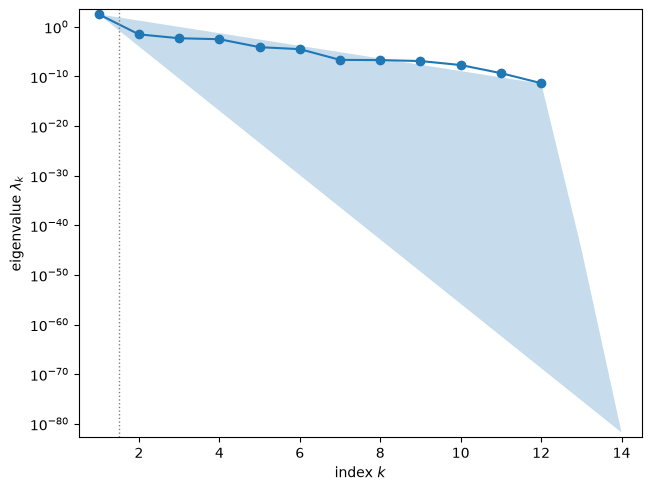

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(subA)
plt.close(fig)
fig

The first eigenvalue is $\lambda_1 = 327.7$ µatm$^2$ and the second $\lambda_2 = 2.97\times10^{-2}$, so $\lambda_1/\lambda_2 = 1.10\times10^{4}$ ($\lambda_2/\lambda_3 = 6.1$), and $\lambda_1$ is 0.999885 of $\mathrm{trace}(\mathbf C) = 327.7$ µatm$^2$. Over measurement uncertainty pCO$_2$ is nearly linear in the inputs, and a linear function has a rank-one $\mathbf C$; the trailing eigenvalues measure how much the gradient direction changes across the samples. $\lambda_{13} = \lambda_{14} = 0$ exactly, because the aragonite and calcite solubility constants do not enter pCO$_2$ and their gradient columns are exactly zero. $\sqrt{\mathrm{trace}\,\mathbf C} = 18.10$ µatm is the sample version of PyCO2SYS's linear propagation (its Eq. 24), which gives 18.08 µatm at the nominal point (`nominal_reference.csv`, printed in the comparison below).

bootstrap mean subspace distance, k = 1..5: 3.04e-04, 1.61e-02, 5.62e-02, 6.90e-03, 2.67e-02


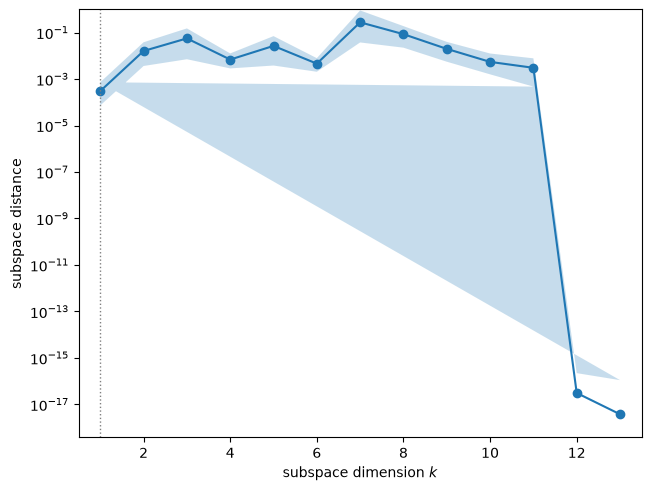

In [7]:
fig, ax = ac.plotting.plot_subspace_errors(subA)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..5:', ', '.join(f'{d:.2e}' for d in subA.bootstrap_distances.mean(axis=0)[:5]))
fig

The bootstrap mean subspace distance for $k = 1$ is $3.0\times10^{-4}$: every replicate returns nearly the same $\mathbf w_1$. The distances for $k = 2$ and 3 ($1.6\times10^{-2}$, $5.6\times10^{-2}$) are larger because the trailing eigenvalues are close to one another ($\lambda_2/\lambda_3 = 6.1$; $\lambda_3 = 4.90\times10^{-3}$, $\lambda_4 = 3.13\times10^{-3}$).

w1: alkalinity -0.312, dic 0.360, temperature 0.064, salinity 0.008, total_silicate 0.002, total_phosphate 0.007, dpk_CO2 0.144, dpk_carbonic_1 0.486, dpk_carbonic_2 -0.660, dpk_borate -0.192, dpk_water -0.013, dpk_aragonite -0.000, dpk_calcite -0.000, f_total_borate 0.200
w1^2 (share of the linearized variance), largest first: dpk_carbonic_2 0.435, dpk_carbonic_1 0.236, dic 0.130, alkalinity 0.097, f_total_borate 0.040, dpk_borate 0.037


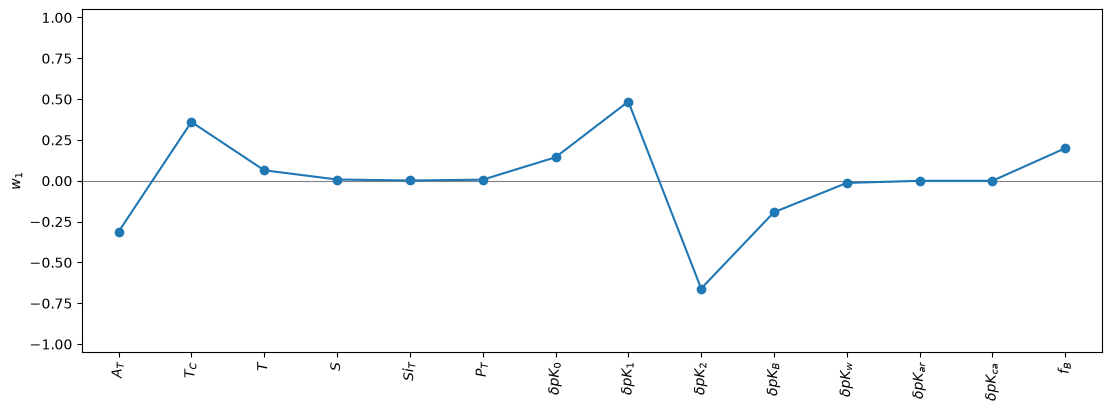

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(subA, indices=[0], labels=labels, figsize=(11, 4))
plt.close(fig)
w1A = subA.W[:, 0]
print('w1:', ', '.join(f'{n} {w:.3f}' for n, w in zip(NAMES, w1A)))
order = np.argsort(-w1A**2)
print('w1^2 (share of the linearized variance), largest first:',
      ', '.join(f'{NAMES[j]} {w1A[j]**2:.3f}' for j in order[:6]))
fig

The weights are the sd-scaled sensitivities of the near-linear model, so $w_{1i}^2$ is input $i$'s share of the linearized variance of pCO$_2$. The two carbonic-acid constants carry most of it: $\delta pK_2^*$ ($w = -0.660$, share 0.435) and $\delta pK_1^*$ ($+0.486$, 0.236), then the measured pair, $T_C$ ($+0.360$, 0.130) and $A_T$ ($-0.312$, 0.097), then total borate ($+0.200$, 0.040) and $\delta pK_B^*$ ($-0.192$, 0.037); $\delta pK_0^*$ has $+0.144$ and temperature $+0.064$. So with 2 µmol kg$^{-1}$ measurements, the uncertainty of the constants, not of the measurements, dominates pCO$_2$ computed from $A_T$ and $T_C$ (with the caveat that the $pK_1^*$, $pK_2^*$ uncertainties are applied to the Sulpis et al. constants by assumption). The signs are the chemistry: pCO$_2$ rises with $T_C$, falls with $A_T$, rises with $pK_1^*$ and with $pK_0^*$ (more CO$_2$(aq) per unit $T_C$; less soluble CO$_2$), and falls with $pK_2^*$.

y range [-3.45, 3.39]; least-squares line: slope 18.0907 uatm, intercept 565.7081 uatm; residual sd 0.4231 uatm (pCO2 sd 18.116 uatm)


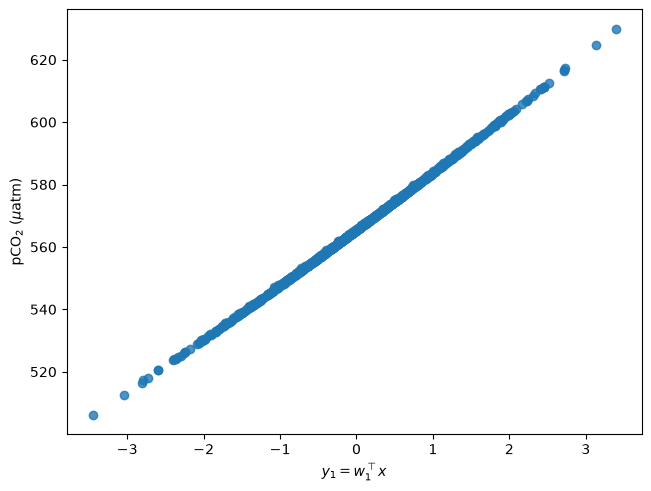

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(subA, X=X['measurement'], f=F['measurement'][:, Q], dims=1,
                                              qoi_label=r'pCO$_2$ ($\mu$atm)')
plt.close(fig)
yA = space['measurement'].to_normalized(X['measurement']) @ w1A
slope, icpt = np.polyfit(yA, F['measurement'][:, Q], 1)
resid = F['measurement'][:, Q] - (slope * yA + icpt)
print(f'y range [{yA.min():.2f}, {yA.max():.2f}]; least-squares line: slope {slope:.4f} uatm, intercept {icpt:.4f} uatm; '
      f'residual sd {resid.std():.4f} uatm (pCO2 sd {F["measurement"][:, Q].std():.3f} uatm)')
fig

The active variable ranges over $[-3.45, 3.39]$, and pCO$_2$ lies on a line in it: least-squares slope 18.09 µatm per unit $y_1$ (close to $\sqrt{\mathrm{trace}\,\mathbf C} = 18.10$), intercept 565.71 µatm (the nominal value is 565.35 µatm), and residual standard deviation 0.42 µatm against a pCO$_2$ standard deviation of 18.12 µatm. The active subspace here is trivially one-dimensional, as expected for a nearly linear model over small uncertainties; its content is the weight vector, which ranks the inputs.

### Results: ocean-wide study (surface ocean, 0 dbar; a parameter study, not an uncertainty study)

The same analysis with the measured inputs spread widely (sd 50 µmol kg$^{-1}$ in $A_T$ and $T_C$, 5 °C, 1 in salinity), the constants as before, and the pressure at 0 dbar.

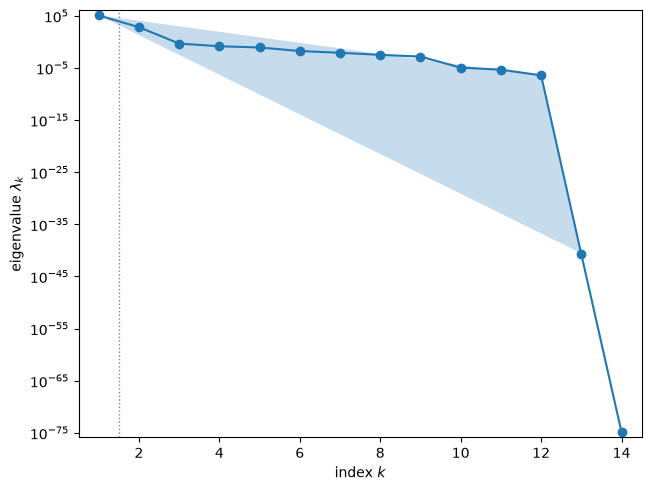

In [10]:
fig, ax = ac.plotting.plot_eigenvalues(subB)
plt.close(fig)
fig

With the wide spread at the sea surface, $\lambda_1 = 1.183\times10^{5}$ µatm$^2$, $\lambda_2 = 670.2$ and $\lambda_3 = 0.479$: $\lambda_1/\lambda_2 = 176.4$ and $\lambda_2/\lambda_3 = 1398$. The default rule compares differences on a linear scale and picks $n = 1$ ($\lambda_1$ is 0.994358 of the trace), so by the printed rule the subspace is one-dimensional; but the larger relative gap is after $\lambda_2$, so a two-dimensional subspace is the better-separated one. The sufficient summary plots and surrogates below compare the two.

bootstrap mean subspace distance, k = 1..5: 3.39e-03, 2.22e-03, 5.18e-02, 7.16e-02, 3.27e-02


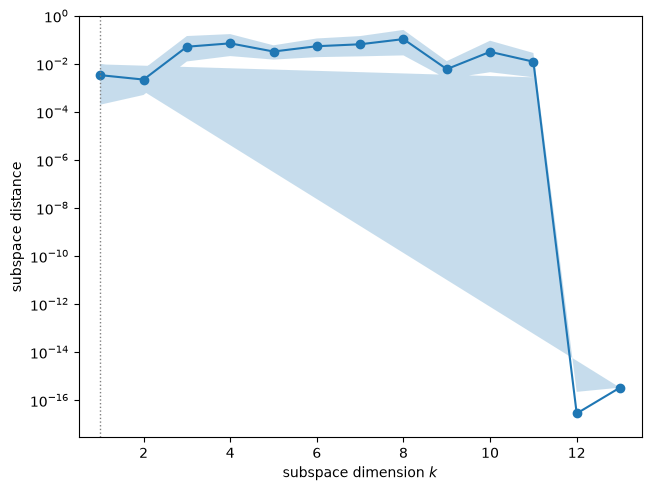

In [11]:
fig, ax = ac.plotting.plot_subspace_errors(subB)
plt.close(fig)
print('bootstrap mean subspace distance, k = 1..5:', ', '.join(f'{d:.2e}' for d in subB.bootstrap_distances.mean(axis=0)[:5]))
fig

The bootstrap mean subspace distances for $k = 1$ and $k = 2$ are $3.4\times10^{-3}$ and $2.2\times10^{-3}$, and $5.2\times10^{-2}$ for $k = 3$: both the one- and the two-dimensional subspaces are stable.

w1: alkalinity -0.610, dic 0.680, temperature 0.401, salinity 0.046, total_silicate 0.001, total_phosphate 0.003, dpk_CO2 0.010, dpk_carbonic_1 0.028, dpk_carbonic_2 -0.039, dpk_borate -0.011, dpk_water -0.001, dpk_aragonite -0.000, dpk_calcite -0.000, f_total_borate 0.011
w2: alkalinity 0.420, dic -0.157, temperature 0.866, salinity 0.143, total_silicate 0.002, total_phosphate -0.001, dpk_CO2 0.015, dpk_carbonic_1 0.094, dpk_carbonic_2 -0.132, dpk_borate -0.034, dpk_water -0.004, dpk_aragonite 0.000, dpk_calcite 0.000, f_total_borate 0.041


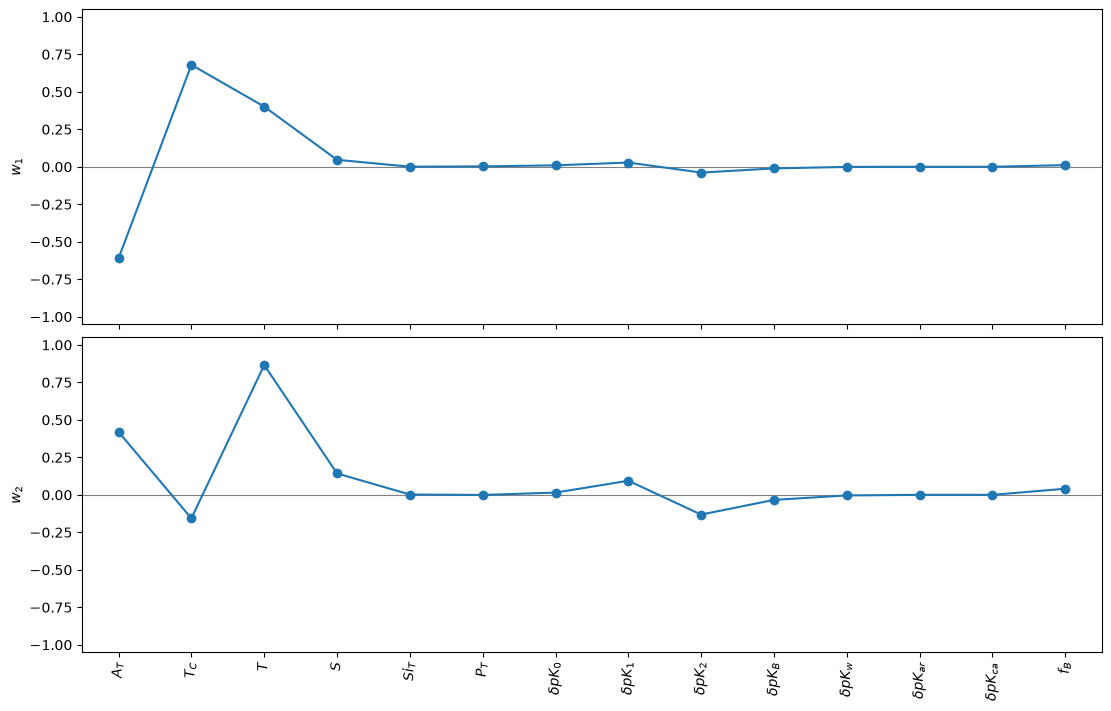

In [12]:
fig, axes = ac.plotting.plot_eigenvectors(subB, indices=[0, 1], labels=labels, figsize=(11, 7))
plt.close(fig)
for k in (0, 1):
    w = subB.W[:, k]
    print(f'w{k + 1}:', ', '.join(f'{n} {v:.3f}' for n, v in zip(NAMES, w)))
fig

The first direction is $T_C - A_T$ plus temperature: $w_1$ has $T_C$ $+0.680$, $A_T$ $-0.610$, $T$ $+0.401$ and salinity $+0.046$. $T_C - A_T$ sets the excess of carbon over the base that can hold it as bicarbonate and carbonate, and warming lowers CO$_2$ solubility. The constants' weights are at most 0.039 in magnitude ($\delta pK_2^*$): their standard uncertainties are tiny next to this spread. The second direction is mostly temperature ($+0.866$), with $A_T$ $+0.420$, $T_C$ $-0.157$, salinity $+0.143$ and the carbonic-acid constants ($\delta pK_2^*$ $-0.132$, $\delta pK_1^*$ $+0.094$). It captures the temperature effect that is not aligned with the carbon excess.

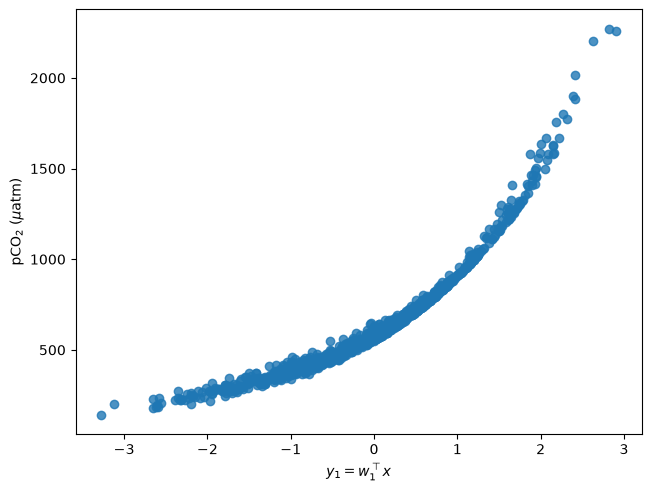

In [13]:
fig, ax = ac.plotting.plot_sufficient_summary(subB, X=X['oceanwide'], f=F['oceanwide'][:, Q], dims=1,
                                              qoi_label=r'pCO$_2$ ($\mu$atm)')
plt.close(fig)
fig

y1 range [-3.27, 2.90], y2 range [-3.43, 2.78]; corr(pCO2, y1) = 0.9306, corr(log pCO2, y1) = 0.9927


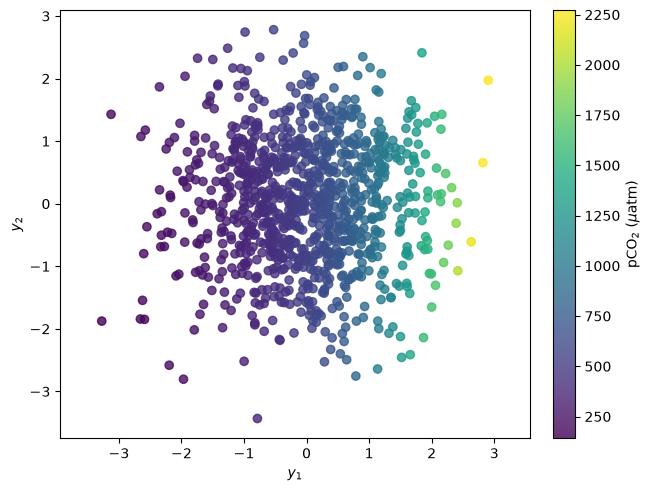

In [14]:
subB2 = subspace('oceanwide', Q, n=2, columns=2)
fig, ax = ac.plotting.plot_sufficient_summary(subB2, X=X['oceanwide'], f=F['oceanwide'][:, Q], dims=2,
                                              qoi_label=r'pCO$_2$ ($\mu$atm)')
plt.close(fig)
YB = space['oceanwide'].to_normalized(X['oceanwide']) @ subB2.W[:, :2]
print(f'y1 range [{YB[:, 0].min():.2f}, {YB[:, 0].max():.2f}], y2 range [{YB[:, 1].min():.2f}, {YB[:, 1].max():.2f}]; '
      f'corr(pCO2, y1) = {np.corrcoef(F["oceanwide"][:, Q], YB[:, 0])[0, 1]:.4f}, '
      f'corr(log pCO2, y1) = {np.corrcoef(np.log(F["oceanwide"][:, Q]), YB[:, 0])[0, 1]:.4f}')
fig

In one dimension (first figure) pCO$_2$ is a convex function of $y_1$ with visible scatter: the correlation of pCO$_2$ with $y_1$ is 0.9306, and that of $\ln$ pCO$_2$ with $y_1$ is 0.9927, so the dependence is close to exponential. In two dimensions (second figure; $y_1 \in [-3.27, 2.90]$, $y_2 \in [-3.43, 2.78]$) the colour changes mainly along $y_1$, and at large $y_1$ also with $y_2$: the scatter of the one-dimensional plot is the second direction. The highest values (pCO$_2$ up to 2271.7 µatm; 111 samples above 1000 µatm) are at the large-$y_1$ end, where $T_C - A_T$ is largest; the 15 samples with $A_T - T_C$ below 50 µmol kg$^{-1}$ have pCO$_2$ from 1262.8 to 2271.7 µatm (printed above), values rare in surface water.

### All four outputs

The same estimator for pH, pCO$_2$ and the two saturation states in both studies (200 bootstrap replicates each), with the dimension the gap rule picks and the three largest weights of $\mathbf w_1$.

In [15]:
rows = {}
for s in STUDIES:
    for q, o in enumerate(OUTS):
        sub = subspace(s, q, nboot=200, columns=1)
        lam, w = sub.eigenvalues, sub.W[:, 0]
        top = np.argsort(-np.abs(w))[:3]
        rows[s, o] = (lam[0] / lam[1], lam[1] / lam[2], sub.n)
        print(f'{s:11s} {o:21s} n = {sub.n}  l1/l2 = {lam[0] / lam[1]:9.4g}  l2/l3 = {lam[1] / lam[2]:7.3g}  '
              f'sqrt(trace C) = {np.sqrt(lam.sum()):9.4g}  w1: ' + ', '.join(f'{NAMES[j]} {w[j]:+.3f}' for j in top))

measurement pH_total              n = 1  l1/l2 =      8447  l2/l3 =    5.72  sqrt(trace C) =   0.01192  w1: dpk_carbonic_2 +0.807, dic -0.363, alkalinity +0.342


measurement pCO2                  n = 1  l1/l2 = 1.104e+04  l2/l3 =    6.06  sqrt(trace C) =      18.1  w1: dpk_carbonic_2 -0.660, dpk_carbonic_1 +0.486, dic +0.360


measurement saturation_aragonite  n = 1  l1/l2 = 2.821e+04  l2/l3 =       6  sqrt(trace C) =   0.09657  w1: dpk_aragonite +0.928, dpk_carbonic_2 -0.229, alkalinity +0.178


measurement saturation_calcite    n = 1  l1/l2 = 2.811e+04  l2/l3 =    6.02  sqrt(trace C) =    0.1463  w1: dpk_calcite +0.928, dpk_carbonic_2 -0.229, alkalinity +0.178


oceanwide   pH_total              n = 1  l1/l2 =     122.9  l2/l3 =     221  sqrt(trace C) =    0.1714  w1: dic -0.654, alkalinity +0.621, temperature -0.421


oceanwide   pCO2                  n = 1  l1/l2 =     176.4  l2/l3 = 1.4e+03  sqrt(trace C) =     344.9  w1: dic +0.680, alkalinity -0.610, temperature +0.401


oceanwide   saturation_aragonite  n = 1  l1/l2 =     702.3  l2/l3 =    13.7  sqrt(trace C) =    0.7158  w1: alkalinity +0.709, dic -0.675, dpk_aragonite +0.158


oceanwide   saturation_calcite    n = 1  l1/l2 =     756.1  l2/l3 =    48.5  sqrt(trace C) =     1.088  w1: alkalinity +0.712, dic -0.677, dpk_calcite +0.158


Over measurement uncertainty all four outputs have a one-dimensional active subspace with $\lambda_1/\lambda_2$ between $8.4\times10^{3}$ (pH) and $2.82\times10^{4}$ ($\Omega_\mathrm{ar}$), as for a nearly linear model. pH is led by $\delta pK_2^*$ ($+0.807$), then $T_C$ and $A_T$; each saturation state by its own solubility constant ($+0.928$), then $\delta pK_2^*$ and $A_T$; $\delta pK_\mathrm{ca}$ does not enter $\Omega_\mathrm{ar}$, nor $\delta pK_\mathrm{ar}$ $\Omega_\mathrm{ca}$. In the surface-ocean study the first direction of every output is the $A_T$–$T_C$ contrast, with temperature third for pH and pCO$_2$ and the mineral's own solubility constant third for the saturation states ($+0.158$). pH has $\lambda_1/\lambda_2 = 122.9$ and $\lambda_2/\lambda_3 = 221$, so its larger relative gap is also after $\lambda_2$, like pCO$_2$; the saturation states have $\lambda_1/\lambda_2 = 702.3$ and 756.1 and smaller second gaps (13.7, 48.5). The gap rule picks $n = 1$ for all eight.

### Surrogates on the active variables

Polynomials in the active variables, with leave-one-out $R^2$: a quadratic in $y_1$ for the measurement study, and cubics in $y_1$ and in $(y_1, y_2)$ for the ocean-wide study.

LOO R^2: measurement, quadratic in y1: 0.99993283; ocean-wide, cubic in y1: 0.99356; cubic in (y1, y2): 0.998955


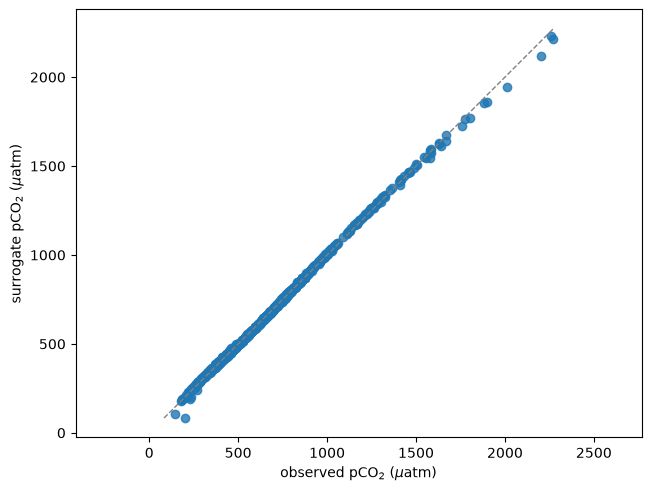

In [16]:
surA = ac.fit_surrogate(X=X['measurement'], f=F['measurement'][:, Q], space=space['measurement'], subspace=subA,
                        kind='poly', degree=2)
surB1 = ac.fit_surrogate(X=X['oceanwide'], f=F['oceanwide'][:, Q], space=space['oceanwide'], subspace=subB,
                         kind='poly', degree=3)
surB2 = ac.fit_surrogate(X=X['oceanwide'], f=F['oceanwide'][:, Q], space=space['oceanwide'], subspace=subB2,
                         kind='poly', degree=3)
print(f'LOO R^2: measurement, quadratic in y1: {surA.loo_r_squared:.8f}; '
      f'ocean-wide, cubic in y1: {surB1.loo_r_squared:.5f}; cubic in (y1, y2): {surB2.loo_r_squared:.6f}')
fig, ax = ac.plotting.plot_surrogate_fit(surB2, X=X['oceanwide'], f=F['oceanwide'][:, Q], qoi_label=r'pCO$_2$ ($\mu$atm)')
plt.close(fig)
fig

For the measurement study a quadratic in $y_1$ has leave-one-out $R^2 = 0.99993283$. For the surface-ocean study a cubic in $y_1$ reaches 0.99356 and a cubic in $(y_1, y_2)$ 0.998955 (figure): the second active variable removes 84 % of the one-dimensional surrogate's unexplained variance ($1 - 0.001045/0.00644$).

### Comparison with the paper

The paper reports no sampling study and no active subspace. It gives the round-robin values at the Table 4 conditions, states that PyCO2SYS's linear propagation agrees with Monte Carlo simulation ($n = 10^4$) to within 3 % (Sect. 4.1.3), and Appendix H gives the forward-difference steps. The cell computes the notebook's values.

In [17]:
from scipy.stats import chi2
T4 = {'pH_total': 7.871, 'pCO2': 572.6, 'fCO2': 570.7, 'xCO2': 587.7, 'carbonate': 143.8,
      'bicarbonate': 1938.5, 'aqueous_CO2': 17.7}
REF_KEYS = ('pH_total', 'pCO2', 'saturation_aragonite', 'saturation_calcite', 'fCO2', 'xCO2',
            'carbonate', 'bicarbonate', 'aqueous_CO2')
for k, v in T4.items():
    i = REF_KEYS.index(k)
    print(f'Table 4 {k:12s} paper {v:>8g}   PyCO2SYS v1.8.3, round-robin set-up {REF[4, i]:.4f}; '
          f'measurement-study nominal (no alpha, beta) {REF[0, i]:.4f}')
for s, sub in (('measurement', subA), ('oceanwide', subB)):
    lin = REF[1 + 2 * STUDIES.index(s)]
    for q, o in enumerate(OUTS):
        lam = subspace(s, q, nboot=0, columns=1).eigenvalues if o != 'pCO2' else sub.eigenvalues
        mc = F[s][:, q].std(ddof=1)
        M = len(F[s])
        lo, hi = mc * np.sqrt((M - 1) / chi2.ppf([0.975, 0.025], M - 1))   # 95 % interval, Gaussian output
        e24 = lin[REF_KEYS.index(o)]
        print(f'{s:11s} {o:21s} sd: Eq. 24 at nominal {e24:.5g}, sqrt(trace C) {np.sqrt(lam.sum()):.5g}, '
              f'Monte Carlo (M = {M}) {mc:.5g} [95 %: {lo:.5g}, {hi:.5g}]; MC / Eq. 24 = {mc / e24:.3f} '
              f'[{lo / e24:.3f}, {hi / e24:.3f}]')
        lin_s = (X[s] - NOMINAL) @ G[s][:, q].mean(axis=0)            # linearized model on the same samples
        print(f'{"":33s} same samples through the linearized model (mean gradient): sd {lin_s.std(ddof=1):.5g}; '
              f'MC / linearized = {mc / lin_s.std(ddof=1):.4f}')

Table 4 pH_total     paper    7.871   PyCO2SYS v1.8.3, round-robin set-up 7.8706; measurement-study nominal (no alpha, beta) 7.8759


Table 4 pCO2         paper    572.6   PyCO2SYS v1.8.3, round-robin set-up 572.6166; measurement-study nominal (no alpha, beta) 565.3469
Table 4 fCO2         paper    570.7   PyCO2SYS v1.8.3, round-robin set-up 570.7219; measurement-study nominal (no alpha, beta) 563.4763
Table 4 xCO2         paper    587.7   PyCO2SYS v1.8.3, round-robin set-up 587.6667; measurement-study nominal (no alpha, beta) 580.2060
Table 4 carbonate    paper    143.8   PyCO2SYS v1.8.3, round-robin set-up 143.7652; measurement-study nominal (no alpha, beta) 145.4018
Table 4 bicarbonate  paper   1938.5   PyCO2SYS v1.8.3, round-robin set-up 1938.5305; measurement-study nominal (no alpha, beta) 1937.1186
Table 4 aqueous_CO2  paper     17.7   PyCO2SYS v1.8.3, round-robin set-up 17.7043; measurement-study nominal (no alpha, beta) 17.4796
measurement pH_total              sd: Eq. 24 at nominal 0.011917, sqrt(trace C) 0.011917, Monte Carlo (M = 1000) 0.011569 [95 %: 0.011083, 0.012099]; MC / Eq. 24 = 0.971 [0.930, 1.015

oceanwide   saturation_aragonite  sd: Eq. 24 at nominal 0.72254, sqrt(trace C) 0.71579, Monte Carlo (M = 1000) 0.72162 [95 %: 0.69132, 0.75472]; MC / Eq. 24 = 0.999 [0.957, 1.045]
                                  same samples through the linearized model (mean gradient): sd 0.71459; MC / linearized = 1.0098
oceanwide   saturation_calcite    sd: Eq. 24 at nominal 1.1059, sqrt(trace C) 1.0882, Monte Carlo (M = 1000) 1.0938 [95 %: 1.0479, 1.144]; MC / Eq. 24 = 0.989 [0.948, 1.034]
                                  same samples through the linearized model (mean gradient): sd 1.0904; MC / linearized = 1.0032


| Quantity | Paper value | Notebook value |
|---|---|---|
| pH$_T$ at the Table 4 conditions | 7.871 (Table 4) | 7.8706 (round-robin set-up); 7.8759 (our studies, without the hypothetical α, β systems) |
| pCO$_2$ (µatm) | 572.6 (Table 4) | 572.6166; 565.3469 |
| fCO$_2$ (µatm) | 570.7 (Table 4) | 570.7219; 563.4763 |
| xCO$_2$ (µmol mol$^{-1}$; Table 4 prints the unit as µatm) | 587.7 (Table 4) | 587.6667; 580.2060 |
| [CO$_3^{2-}$] (µmol kg$^{-1}$) | 143.8 (Table 4) | 143.7652; 145.4018 |
| [HCO$_3^-$] (µmol kg$^{-1}$) | 1938.5 (Table 4) | 1938.5305; 1937.1186 |
| [CO$_2$(aq)] (µmol kg$^{-1}$) | 17.7 (Table 4) | 17.7043; 17.4796 |
| Linear propagation vs Monte Carlo | within 3 % (Sect. 4.1.3, $n = 10^4$, constants and all input pairs) | pCO$_2$, measurement study: Eq. 24 18.08 µatm, Monte Carlo 18.13 [17.36, 18.96] µatm (ratio 1.002) |
| Uncertainty of pCO$_2$, pH, $\Omega$ at these conditions | not reported | Eq. 24: 18.08 µatm, 0.0119, 0.0963 ($\Omega_\mathrm{ar}$) |
| Active subspace | not reported | measurement: $n = 1$, $\lambda_1/\lambda_2 = 1.10\times10^{4}$; surface ocean: $n = 1$ by the gap rule, $\lambda_1/\lambda_2 = 176.4$, $\lambda_2/\lambda_3 = 1398$ |

With PyCO2SYS v1.8.0's default options and the round-robin script's two hypothetical acid–base systems ("round-robin set-up", `nominal_reference.csv` row 4), PyCO2SYS v1.8.3 reproduces all seven printed Table 4 values: each rounds to the printed digits (pH 7.8706 → 7.871, [CO$_3^{2-}$] 143.7652 → 143.8, pCO$_2$ 572.6166 → 572.6), consistent with the script's table code, which prints pH with three decimals and the rest with one. The Table 4 caption does not list the two hypothetical systems; without them (our studies' nominal point) pH is 0.005 higher and pCO$_2$ 7.27 µatm lower. The paper's Table 4 gives xCO$_2$ in µatm; xCO$_2$ is a dry-air mole fraction, so its unit is µmol mol$^{-1}$, as in `nominal_reference.csv`.

Over measurement uncertainty the Monte Carlo standard deviations agree with PyCO2SYS's linear propagation to within the 95 % sampling intervals of a 1000-sample estimate for pH and pCO$_2$ (ratios 0.971 and 1.002); the saturation states are at the edge (1.044 [1.000, 1.092] and 1.049 [1.005, 1.097]). The cause is sampling, not nonlinearity: the same samples passed through the linearized model give standard deviations within 0.13 % of the Monte Carlo ones for all four outputs (ratios 0.9987–1.0001). In the surface-ocean study linear propagation at the nominal point underestimates the pCO$_2$ spread (308.91 against 248.07 µatm, ratio 1.245 [1.193, 1.302]) because pCO$_2$ is convex in the active variable; this is outside the regime the paper's Eq. (24) is meant for. For pH and the saturation states the ratios are 1.024, 0.999 and 0.989, within their intervals.

### References

[1] M. P. Humphreys, E. R. Lewis, J. D. Sharp, and D. Pierrot. [PyCO2SYS v1.8: marine carbonate system calculations in Python](https://doi.org/10.5194/gmd-15-15-2022). *Geoscientific Model Development*, 15(1):15–43, 2022.

[2] J. C. Orr, J.-M. Epitalon, A. G. Dickson, and J.-P. Gattuso. [Routine uncertainty propagation for the marine carbon dioxide system](https://doi.org/10.1016/j.marchem.2018.10.006). *Marine Chemistry*, 207:84–107, 2018. (Not read for this notebook; the standard uncertainties are those PyCO2SYS v1.8.3 ships under this name.)

[3] O. Sulpis, S. K. Lauvset, and M. Hagens. [Current estimates of K1* and K2* appear inconsistent with measured CO2 system parameters in cold oceanic regions](https://doi.org/10.5194/os-16-847-2020). *Ocean Science*, 16(4):847–862, 2020.

[4] L. R. Uppström. [The boron/chlorinity ratio of deep-sea water from the Pacific Ocean](https://doi.org/10.1016/0011-7471(74)90074-6). *Deep Sea Research and Oceanographic Abstracts*, 21(2):161–162, 1974.

[5] A. G. Dickson and J. P. Riley. [The estimation of acid dissociation constants in sea-water media from potentiometric titrations with strong base. II. The dissociation of phosphoric acid](https://doi.org/10.1016/0304-4203(79)90002-1). *Marine Chemistry*, 7(2):101–109, 1979. (Cited by the paper and PyCO2SYS for $K_{HF}^*$, `opt_k_fluoride=1`.)

[6] A. G. Dickson. [Standard potential of the reaction: AgCl(s) + ½H2(g) = Ag(s) + HCl(aq), and the standard acidity constant of the ion HSO4− in synthetic sea water from 273.15 to 318.15 K](https://doi.org/10.1016/0021-9614(90)90074-Z). *The Journal of Chemical Thermodynamics*, 22(2):113–127, 1990.

[7] M. P. Humphreys, A. J. Schiller, D. Sandborn, L. Gregor, D. Pierrot, S. M. A. C. van Heuven, E. R. Lewis, and D. W. R. Wallace. PyCO2SYS: marine carbonate system calculations in Python (v1.8.0). Zenodo [code], 2021. https://doi.org/10.5281/zenodo.5602840. Code at <https://github.com/mvdh7/PyCO2SYS> (GPLv3); the data here were written with v1.8.3 from PyPI.

[8] P. G. Constantine. [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860). SIAM, 2015.

[9] J. Orr, J.-P. Gattuso, J.-M. Epitalon, and H. Lavigne. seacarb: Seawater Carbonate Chemistry. R package version 3.4.1, 2026. <https://CRAN.R-project.org/package=seacarb> (function `errors()`: default uncertainties eS = 0.01, eT = 0.01 °C, and the same pK* and 2 % borate uncertainties as `uncertainty_OEDG18`).

[R1]: https://doi.org/10.5194/gmd-15-15-2022
[R2]: https://doi.org/10.1016/j.marchem.2018.10.006
[R3]: https://doi.org/10.5194/os-16-847-2020
[R4]: https://doi.org/10.1016/0011-7471(74)90074-6
[R5]: https://doi.org/10.1016/0304-4203(79)90002-1
[R6]: https://doi.org/10.1016/0021-9614(90)90074-Z
[R7]: https://doi.org/10.5281/zenodo.5602840
[R9]: https://CRAN.R-project.org/package=seacarb

### Acknowledgments

The paper's Acknowledgements (p. 41) read: "We thank Doug Wallace for providing useful comments on this paper, and we acknowledge his important role in the creation of the original CO2SYS software. We further acknowledge the developers of all subsequent versions of CO2SYS upon whose work PyCO2SYS was built. We thank Luke Gregor, Daniel Sandborn, and Abigail Schiller for code contributions including extending the range of data types with which PyCO2SYS can be used. We are grateful to Guy Munhoven and James Orr for their detailed and constructive reviews." The paper gives no funding statement.

In [18]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 9.8 s
